In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("C:/Users/S.YUVADEEP/OneDrive/Documents/hotel_bookings.csv")

print(df.head())

          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                        0                     0       2  ...    No Deposit   
1     

In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (119390, 32)

Column Names:
Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

Data Types:
hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_n

In [9]:
# Numerical columns
num_cols = df.select_dtypes(include=np.number).columns

# Categorical columns
cat_cols = df.select_dtypes(include='str').columns

# Fill numerical missing values using median
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values
for col in cat_cols:
    df[col] = df[col].fillna('Unknown')

# Check missing values
print("Total Missing Values:", df.isnull().sum())

Total Missing Values: hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr   

In [10]:
selected_cols = [
    'lead_time',
    'adr',
    'adults',
    'stays_in_week_nights'
]

print(df[selected_cols].head())

   lead_time   adr  adults  stays_in_week_nights
0        342   0.0       2                     0
1        737   0.0       2                     0
2          7  75.0       1                     1
3         13  75.0       1                     1
4         14  98.0       2                     2


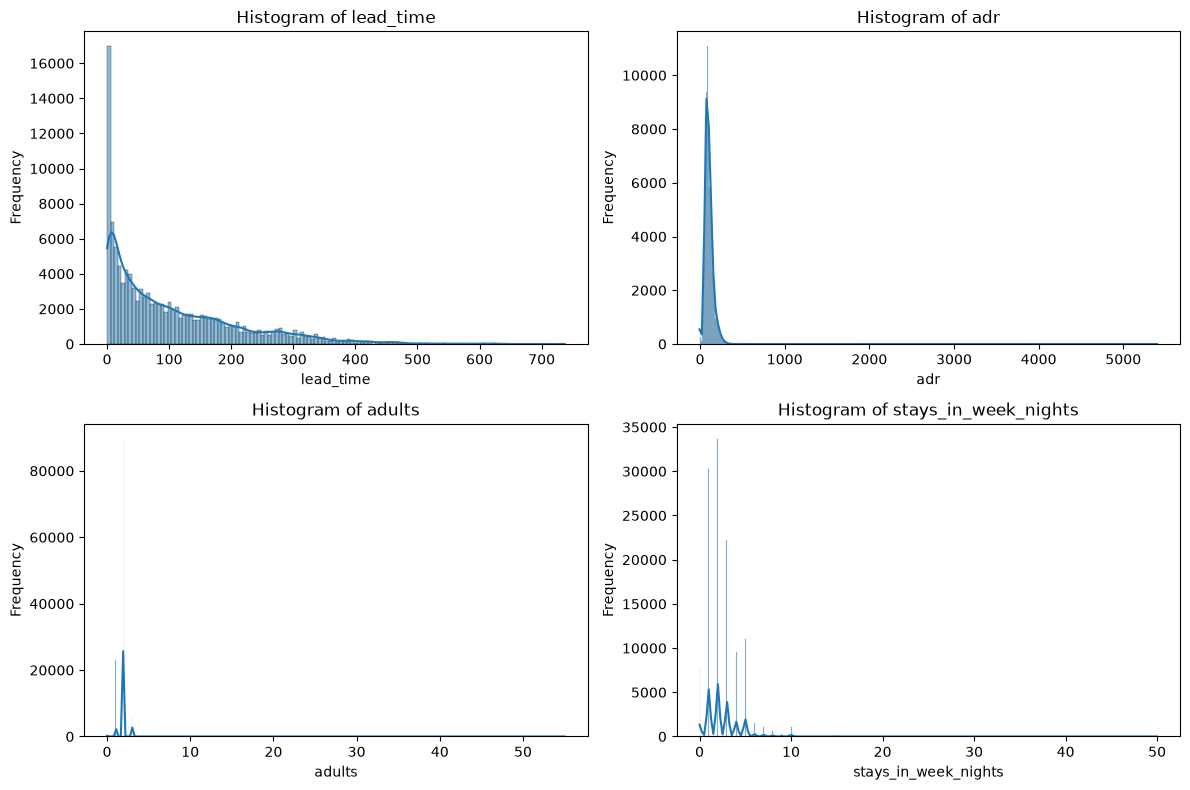

In [11]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(selected_cols):
    plt.subplot(2, 2, i+1)

    sns.histplot(df[col], kde=True)

    plt.title("Histogram of " + col)
    plt.xlabel(col)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

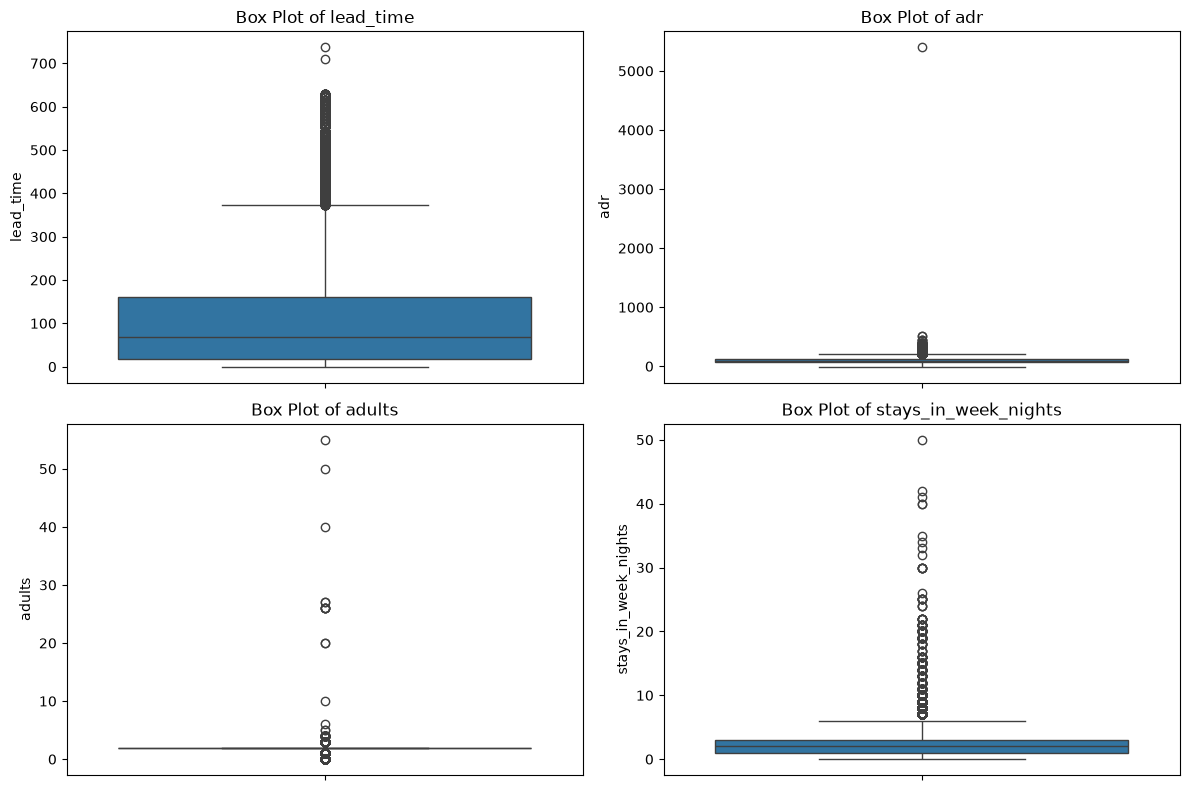

In [12]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(selected_cols):
    plt.subplot(2, 2, i+1)

    sns.boxplot(y=df[col])

    plt.title("Box Plot of " + col)
    plt.ylabel(col)

plt.tight_layout()
plt.show()

In [13]:
print("Skewness of Numerical Columns:")

for col in selected_cols:
    print(col, ":", df[col].skew())

Skewness of Numerical Columns:
lead_time : 1.3465498727254264
adr : 10.53021398218952
adults : 18.317804759206098
stays_in_week_nights : 2.8622492420671244


In [14]:
print("Kurtosis of Numerical Columns:")

for col in selected_cols:
    print(col, ":", df[col].kurtosis())

Kurtosis of Numerical Columns:
lead_time : 1.696448848558545
adr : 1013.1898508588172
adults : 1352.1151163093687
stays_in_week_nights : 24.284554815417337
